# Introduction
La légende urbaine veut que plus de 5 millions de rats vivent à Paris, ce qui équivaut à plus d'un rat et demi par habitant. Paris se placerait alors en quatrième position des villes avec le plus de rats, derrière Londres, New-York et Deshnoke (en Inde). Ce chiffre de 5 millions, largement répété mais dont la source est difficile à établir, alimente l'association d'idées entre Paris et les rongeurs dans un sens plus négatif que le film _Ratatouille_ sorti en 2007. Face à cela, depuis 2017, la Ville de Paris renforce ses actions anti-rats avec un plan d'actions. Pour limiter la prolifération des rongeurs, la municipalité a multiplié ses interventions et s'appuie sur une application nommée "Dans ma rue" qui permet à chacun de signaler des dégradations dans l'espace public, ainsi que la présence de rats. 

La présence de rats étant un vrai fléau pour Paris et un enjeu actuel, nous avons choisi de nous pencher sur ce sujet pour savoir s'il était possible de "prédire" la présence d'un rat à un moment donné, à un lieu donné. Il nous a semblé raisonnable d'élargir ce que nous avons trouvé dans la base de données initiale (Dans Ma Rue) pour y inclure des variables qui nous semblent être pertinentes pour prédire la présence de rats. L'imaginaire du rat de gouttière qui aime les environnements humides et les poubelles nous a aiguillé dans la sélection de ces angles d'analyse complémentaires. En plus des dates et des coordonées GPS des signalements de rats, nous  nous sommes concentrés sur des données météorologiques et géographiques plus adaptées à l'espace urbain parisien. A elles seules, ces variables suffisent-elles à prédire le prochain signalement de rat ? 


PAS FINIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII
Pour répondre à cette question, nous décrirons tout d'abord les observations faites 





# 1. Premières observations
## 1.1. Préparation des données

Avant de commencer, une précision nous semble importante à faire : ici, nous n'étudions que la présence de rats ayant été signalés. Cela peut donc induire des biais que nous ne pouvons pas détecter : en effet, il ne semble pas impossible que les personnes qui signalent davantage des rats partagent des caractéristiques géographiques ou socio-démographiques. 

In [13]:
import pandas as pd

data2012 = pd.read_csv('Data/DMR_2012.csv', sep=";", encoding='utf-8')
data2013 = pd.read_csv('Data/DMR_2013.csv', sep=";", encoding='utf-8')
data2014 = pd.read_csv('Data/DMR_2014.csv', sep=";", encoding='utf-8')
data2015 = pd.read_csv('Data/DMR_2015.csv', sep=";", encoding='utf-8')
data2016 = pd.read_csv('Data/DMR_2016.csv', sep=";", encoding='utf-8')
data2017 = pd.read_csv('Data/DMR_2017.csv', sep=";", encoding='utf-8')
data2018 = pd.read_csv('Data/DMR_2018.csv', sep=";", encoding='utf-8')
data2019 = pd.read_csv('Data/DMR_2019.csv', sep=";", encoding='utf-8')
data2020 = pd.read_csv('Data/DMR_2020.csv', sep=";", encoding='utf-8')
data2021 = pd.read_csv('Data/DMR_2021.csv', sep=";", encoding='utf-8')
data2022 = pd.read_csv('Data/DMR_2022.csv', sep=";", encoding='cp1252')
data2023 = pd.read_csv('Data/DMR_2023.csv', sep=";", encoding='cp1252')
data2024 = pd.read_csv('Data/DMR_2024.csv', sep=";", encoding='utf-8')
data2025 = pd.read_csv('Data/DMR_2025.csv', sep=";", encoding='utf-8')

# HARMONISATION DES COLONNES

datas = {f"data20{i}": globals()[f"data20{i}"] for i in range(12, 26)}

for i in range(12, 26):
    # on met tous les noms de colonnes en majuscule
    datas[f"data20{i}"].columns = datas[f"data20{i}"].columns.str.upper()

# Harmonisation des formats date
for data in datas.values():
    # On voir une forte hétérogénéité des formats de date
    data["DATEDECL"] = pd.to_datetime(data["DATEDECL"], format="mixed", errors="coerce")
    data["JOURDECL"] = data["DATEDECL"].dt.day


liste_colonnes = ["ID_DMR", "TYPE", "SOUSTYPE", "ADRESSE", "CODE_POSTAL", "VILLE", "ARRONDISSEMENT",
                  "DATEDECL", "ANNEEDECL", "MOISDECL", "JOURDECL", "CONSEILQUARTIER", "X", "Y"]

for i in range(12, 26):
    datas[f"data20{i}"] = datas[f"data20{i}"][liste_colonnes]


######## IDENTIFICATION DES LIGNES SIGNALANT UNE PRESENCE DE RATS

sous_types_pertinents = {}
for i in range(12, 26):
    df = datas[f"data20{i}"]
    sous_types = df["SOUSTYPE"].dropna().unique()
    sous_types_pertinents[f"20{i}"] = [s for s in sous_types if isinstance(s, str) and (" rat" in s.lower() or " rats" in s.lower() or " souris" in s.lower()) and ("ratp" not in s.lower())]

sous_types_pertinents_uniques = []
for s in sous_types_pertinents.values():
    for u in s:
        if u not in sous_types_pertinents_uniques:
            sous_types_pertinents_uniques.append(u)

# on trouve : [' Présence de rats', ' Présence de souris', 
# " Autres problèmes d'animaux et d'insectes : [] Rats sortant des égouts"]

# SELECTION DES LIGNES PERTINENTES SELON LE SOUS TYPE

for i in range(12, 26):
    df = datas[f"data20{i}"]
    datas[f"data20{i}"] = df[df["SOUSTYPE"].isin(sous_types_pertinents_uniques)]

# CONSTRUCTION DU FICHIER PROPRE
data_clean = pd.concat([datas[f"data20{i}"] for i in range(12, 26)])
print(data_clean.sample(n=20))

# retouches finales:

# test présence NaN
na_counts = data_clean.isna().sum()
print(na_counts[na_counts > 0].sort_values(ascending=False))

# conversion en nombres

def to_num(s: pd.Series) -> pd.Series:
    return pd.to_numeric(
        s.astype(str).str.strip().str.replace(",", ".", regex=False),
        errors="coerce",
    )
data_clean["ARRONDISSEMENT"] = to_num(data_clean["ARRONDISSEMENT"])
data_clean["CODE_POSTAL"] = to_num(data_clean["CODE_POSTAL"])
data_clean["X"] = to_num(data_clean["X"]) #X: longitude
data_clean["Y"] = to_num(data_clean["Y"]) #Y: latitude
# vérification de conversion
print(data_clean.dtypes)  # tout va bien

# pour toute colonne, affiche la proptable
for col in data_clean.columns.drop(["ADRESSE", "X", "Y"]):
    print(f"--- {col} ---")
    print(data_clean[col].value_counts(normalize=True, dropna=False).round(5)*100)
    print("____done____")
# les problèmes de type "75116" "75116.0" "75116,0000" sont résolus

# test présence NaN
na_counts = data_clean.isna().sum()
print("na counts", na_counts[na_counts > 0].sort_values(ascending=False))
# aucun NaN n'est apparu


# on regarde le ID_DMR qui apparaît 2 fois, (constaté dans les proptables précédentes)

# print(data_clean.loc[data_clean["ID_DMR"]=="S2017D000601",:])
# c'est bien la même ligne, on vire le dupliqué
print(data_clean.shape)
data_clean = data_clean.drop_duplicates(subset="ID_DMR")
print(data_clean.shape)  # suppression effective

# réunion des valeurs similaires de SOUSTYPE:

# rappel distribution
print(data_clean["SOUSTYPE"].value_counts(normalize=True, dropna=False).round(5)*100)

# on réecrit les catégories
data_clean.loc[data_clean["SOUSTYPE"] == " Présence de rats", "SOUSTYPE"] = "Présence de rats"
data_clean.loc[data_clean["SOUSTYPE"] == " Présence de souris", "SOUSTYPE"] = "Présence de souris"
data_clean.loc[data_clean["SOUSTYPE"].str.contains("égouts", na=False), "SOUSTYPE"] = "Rats sortant des égouts"

# affichage proptable, a-ce fonctionné? oui!
print(data_clean["SOUSTYPE"].value_counts(normalize=True, dropna=False).round(5)*100)


# l'info de VILLE est redondante à celle de ARRONDISSEMENT, on supprime VILLE
data_clean = data_clean.drop(columns=["VILLE"])

# final check:
print(data_clean.dtypes)
print(data_clean.shape)
for col in data_clean.columns.drop(["ADRESSE", "X", "Y"]):
    print(f"--- CHECK FINAL: {col} ---")
    print(data_clean[col].value_counts(normalize=True, dropna=False).round(5)*100)
    print(f"____FIN CHECK FINAL: {col}____")
# tout paraît ok

data_clean.to_csv('Data/clean_rats.csv')

               ID_DMR                         TYPE             SOUSTYPE  \
144984   A2023D053730  Arbres, végétaux et animaux     Présence de rats   
1855043  G2025F114913  Arbres, végétaux et animaux     Présence de rats   
1656509  A2025K113861  Arbres, végétaux et animaux     Présence de rats   
351617   S2019I015797  Arbres, végétaux et animaux     Présence de rats   
404058   A2021F084641  Arbres, végétaux et animaux     Présence de rats   
140436   S2020D000841  Arbres, végétaux et animaux     Présence de rats   
291252   S2020G039792  Arbres, végétaux et animaux     Présence de rats   
280259   A2023F029017  Arbres, végétaux et animaux     Présence de rats   
155015   S2018I013759  Arbres, végétaux et animaux     Présence de rats   
90227    A2024F088931  Arbres, végétaux et animaux     Présence de rats   
137327   S2018H017181  Arbres, végétaux et animaux     Présence de rats   
167780   G2018I026628  Arbres, végétaux et animaux     Présence de rats   
257585   A2024L036858  Ar

## 1.2. Proportion de signalements en fonction des variables étudiées
Pour avoir une première analyse un peu plus fine, regardons la proportion de signalements en fonction des variables.

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

data = pd.read_csv("Data/clean_rats.csv")
# Se familiariser avec les données :
print(data.sample(3))
print(data.dtypes)

      Unnamed: 0        ID_DMR                         TYPE  \
2561      109376  S2018G014459  Arbres, végétaux et animaux   
857        54358  S2016J002929  Arbres, végétaux et animaux   
7577      820987  A2022L034055  Arbres, végétaux et animaux   

                SOUSTYPE                               ADRESSE  CODE_POSTAL  \
2561    Présence de rats      48 quai de la Marne, 75019 PARIS      75019.0   
857     Présence de rats      4 avenue emile zola, 75015 PARIS      75015.0   
7577  Présence de souris  45 Avenue de Versailles, 75016 PARIS      75016.0   

      ARRONDISSEMENT    DATEDECL  ANNEEDECL  MOISDECL  JOURDECL  \
2561            19.0  2018-07-18       2018         7        18   
857             15.0  2016-10-13       2016        10        13   
7577            16.0  2022-12-18       2022        12        18   

     CONSEILQUARTIER         X          Y  
2561  MANIN - JAURES  2.385557  48.891026  
857   EMERIAU - ZOLA  2.277981  48.846043  
7577    AUTEUIL NORD  2.27533

In [15]:
# Pour chaque colonne où c'est pertinent, on affiche les proportions par groupe
for col in data.columns.drop(["ID_DMR", "DATEDECL", "CODE_POSTAL", "TYPE", "JOURDECL", "ADRESSE", "X", "Y"]):
    print(f"--- {col} ---")
    print(data[col].value_counts(normalize=True, dropna=False).round(5)*100)
    print("____done____")

--- Unnamed: 0 ---
Unnamed: 0
45329      0.027
64286      0.027
30924      0.018
34010      0.018
47201      0.018
           ...  
1906381    0.009
1906617    0.009
1911616    0.009
1913242    0.009
1913376    0.009
Name: proportion, Length: 11013, dtype: float64
____done____
--- SOUSTYPE ---
SOUSTYPE
Présence de rats           94.737
Présence de souris          4.920
Rats sortant des égouts     0.342
Name: proportion, dtype: float64
____done____
--- ARRONDISSEMENT ---
ARRONDISSEMENT
15.0    9.931
17.0    8.966
19.0    8.101
18.0    8.065
20.0    7.525
12.0    7.254
11.0    6.957
13.0    5.993
14.0    5.506
10.0    5.434
1.0     4.632
4.0     4.190
16.0    4.091
5.0     3.082
9.0     2.586
2.0     1.730
3.0     1.658
8.0     1.577
6.0     1.397
7.0     1.325
Name: proportion, dtype: float64
____done____
--- ANNEEDECL ---
ANNEEDECL
2023    11.237
2025    11.021
2019    10.931
2022    10.868
2018     9.985
2021     9.750
2017     9.705
2024     9.309
2020     7.389
2016     6.416
2015  

On voit qu'en grande majorité (à 94,74%), les signalements sont de type "Présence de rats". La présence de souris est très rare et la mention "rats sortant des égouts" est quasiment négligeable. Cela peut-être dû à une méconnaissance, à la fois du rongeur aperçu puis signalé, ainsi qu'à une méconnaissance des catégories proposées par la plateforme. En effet, la proportion de "rats sortant des égouts" semble particulièrement faible alors même que la ville de Paris intervient régulièrement dans les égouts pour dératiser, attestant par là la présence même de rats dans ces lieux. De plus, on peut voir que l'arrondissement le plus infesté de la capitale est le 15e (qui recense 9,93% des signalements alors que le 7ème n'en concentre que 1,33%). A première lecture, on voit aussi que c'est lors des mois d'août, septembre et octobre que les signalements sont les plus nombreux. On peut alors tracer un tableau présentant les moments et les lieux où les signalements ont été plus et moins importants. 

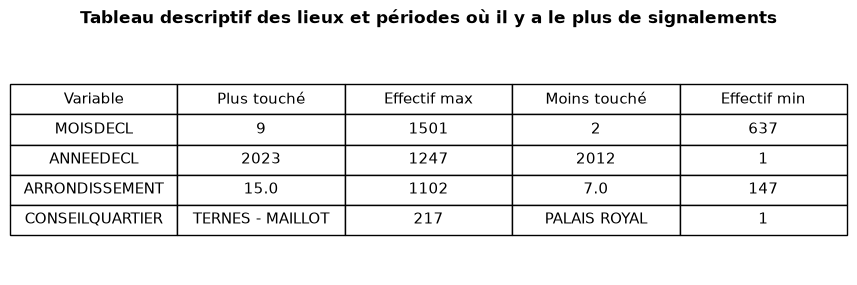

In [16]:
# On veut regarder les mois, années, arrondissements et quartier les plus
# et moins touchés pour davantage de lisibilité. Sous forme de tableau.
colonnes = ['MOISDECL', "ANNEEDECL", 'ARRONDISSEMENT', 'CONSEILQUARTIER']
resultats = []
for col in colonnes:
    groupes = data.groupby(col, dropna=False).size()
    plus = groupes.idxmax()
    moins = groupes.idxmin()
    resultats.append([col, str(plus), int(groupes.max()),
                      str(moins), int(groupes.min())])
maximin = pd.DataFrame(
    resultats,
    columns=['Variable', 'Plus touché', 'Effectif max', 'Moins touché', 'Effectif min'])

fig, ax = plt.subplots(figsize=(6, 3))
ax.axis('off')
ax.set_title("Tableau descriptif des lieux et périodes où il y a le plus de signalements",
             fontweight='bold', pad=15)
tab = ax.table(
    cellText=maximin.values,
    colLabels=maximin.columns,
    cellLoc='center',
    loc='center',
    colWidths=[0.30, 0.30, 0.30, 0.30, 0.30]
)
tab.auto_set_font_size(False)
tab.set_fontsize(11)
tab.scale(1.2, 1.8)

plt.savefig('Outputs/tableau_extrema.png',
            dpi=300,
            bbox_inches='tight',
            transparent=False)
plt.show()
plt.close()

On voit que les signalements sont plus élevés en 2023 qu'en 2012. En regardant les proptables faites précédemment, on constate que seulement 0.009% des observations ont été réalisées en 2012, ce qui ne représente qu'un seul signalement. Il semble plus cohérent de penser que c'est dû à une faible popularité de la plateforme liée à son inauguration plutôt qu'à une très faible présence de rats dans la capitale. En s'intéressant plus précisément aux quartiers de signalements, on voit que Ternes-Maillot concentre plus de 200 signalements quand le Palais Royal n'en a qu'une seule. A ce stade, il semble difficile d'estimer la raison de cette disparité. On peut faire des hypothèses sur la présence de restaurants ou d'espaces verts inégalement répartis entre ces deux quartiers, ce qui sera approfondi plus loin.


## 1.3. Evolution du nombre de signalements au cours du temps
Ce que cette base de données nous permet d'ores et déjà d'étudier est l'évolution du nombre de signalements au cours du temps. On s'intéresse d'une part à l'évolution au cours des années. 

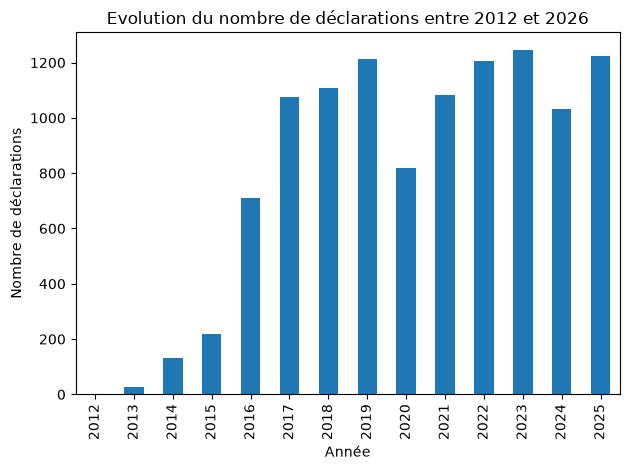

In [ ]:
# EVOLUTION DU NOMBRE DE SIGNALEMENTS PAR AN
axe = data['ANNEEDECL'].value_counts().sort_index().plot.bar()
axe.set_xlabel("Année")
axe.set_ylabel("Nombre de déclarations")
axe.set_title("Evolution du nombre de déclarations entre 2012 et 2025")
plt.tight_layout()
plt.savefig("Outputs/Evolution_nombre_declarations_année.png", dpi=150)
plt.show()


L'augmentation du nombre entre 2013 et 2017 est vraisemblablement dûe à une popularisation de la plateforme. On voit également l'effet de la pandémie dans ces données : entre 2019 et 2020, les signalements de rats ont largement diminué puis dès 2021, le nombre de signalements à retrouvé ses valeurs habituelles. 
On peut prendre un autre angle d'analyse afin d'étudier les périodes où les rats sont davantage de sortie au cours d'une même année. Pour cela, on regarde le nombre total de signalements par mois (en accumulant les années) et on trace la moyenne pour avoir une idée de ce que cela représenterait sur une année représentative. 


([<matplotlib.collections.LineCollection object at 0x7f1e1a028ec0>, <BarContainer object of 12 artists>], ['Moyenne mensuelle', 'count'])
2
['Moyenne mensuelle', 'count']


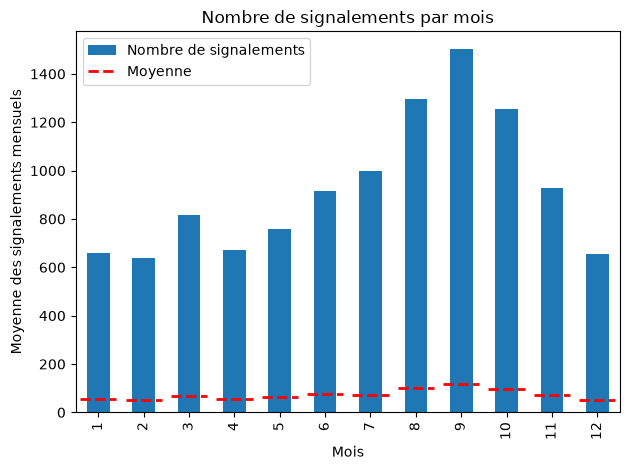

mois le plus infesté : 9, en moyenne 115.46153846153847 signalements.
mois le moins infesté : 12, en moyenne 50.46153846153846 signalements


In [18]:
# HISTOGRAMME D NOMBRE DE SIGNALEMENTS PAR MOIS, TOUTES ANNEES CONFONDUES
# calculons les moyennes mensuelles
comptages = data.groupby(['ANNEEDECL', 'MOISDECL']).size()
moyennes = comptages.groupby('MOISDECL').mean()
axe = data['MOISDECL'].value_counts(normalize=False).sort_index().plot.bar()
for i, moyenne in enumerate(moyennes):
    axe.hlines(
        y=moyenne,
        xmin=i-0.4,
        xmax=i+0.4,
        color='red',
        linestyle='--',
        linewidth=2,
        label='Moyenne mensuelle' if i == 0 else None
    )
axe.set_title('Nombre cumulé de signalements par mois')
axe.set_xlabel("Mois")
axe.set_ylabel("Moyenne des signalements mensuels")
handles, labels = axe.get_legend_handles_labels()
# pour pouvoir personnaliser la légende
axe.legend(
    handles=[handles[1], handles[0]],
    labels=['Nombre de signalements', 'Moyenne'],
    loc='best'
)
plt.tight_layout()
plt.savefig("Outputs/Signalements_par_mois.png", dpi=150)
plt.show()
print(f"mois le plus infesté : {moyennes.idxmax()}, en moyenne {moyennes.max()} signalements.")
print(f"mois le moins infesté : {moyennes.idxmin()}, en moyenne {moyennes.min()} signalements")


Lors du mois où les signalements sont les plus fréquents, en septembre, on a en moyenne 115.5 signalements chaque année. A contrario, en décembre (mois le moins infesté), il y a seulement 50.5 signalements en moyenne par an, soit 2,29 fois moins qu'en septembre. On voit ainsi une certaine dispersion des moyennes mensuelles. On peut faire l'hypothèse (ui sera testée par la suite), que le froid est moins propice à la sortie des rats, et que les rongeurs préfèrent la chaleur. 
Enfin, on peut croiser les deux graphiques précédents en s'intéressant à l'évolution du nombre de signalements par an en fonction des saisons. On peut comparer les fréquences à la tendance générale qui s'était dégagée dans le premier histogramme. 


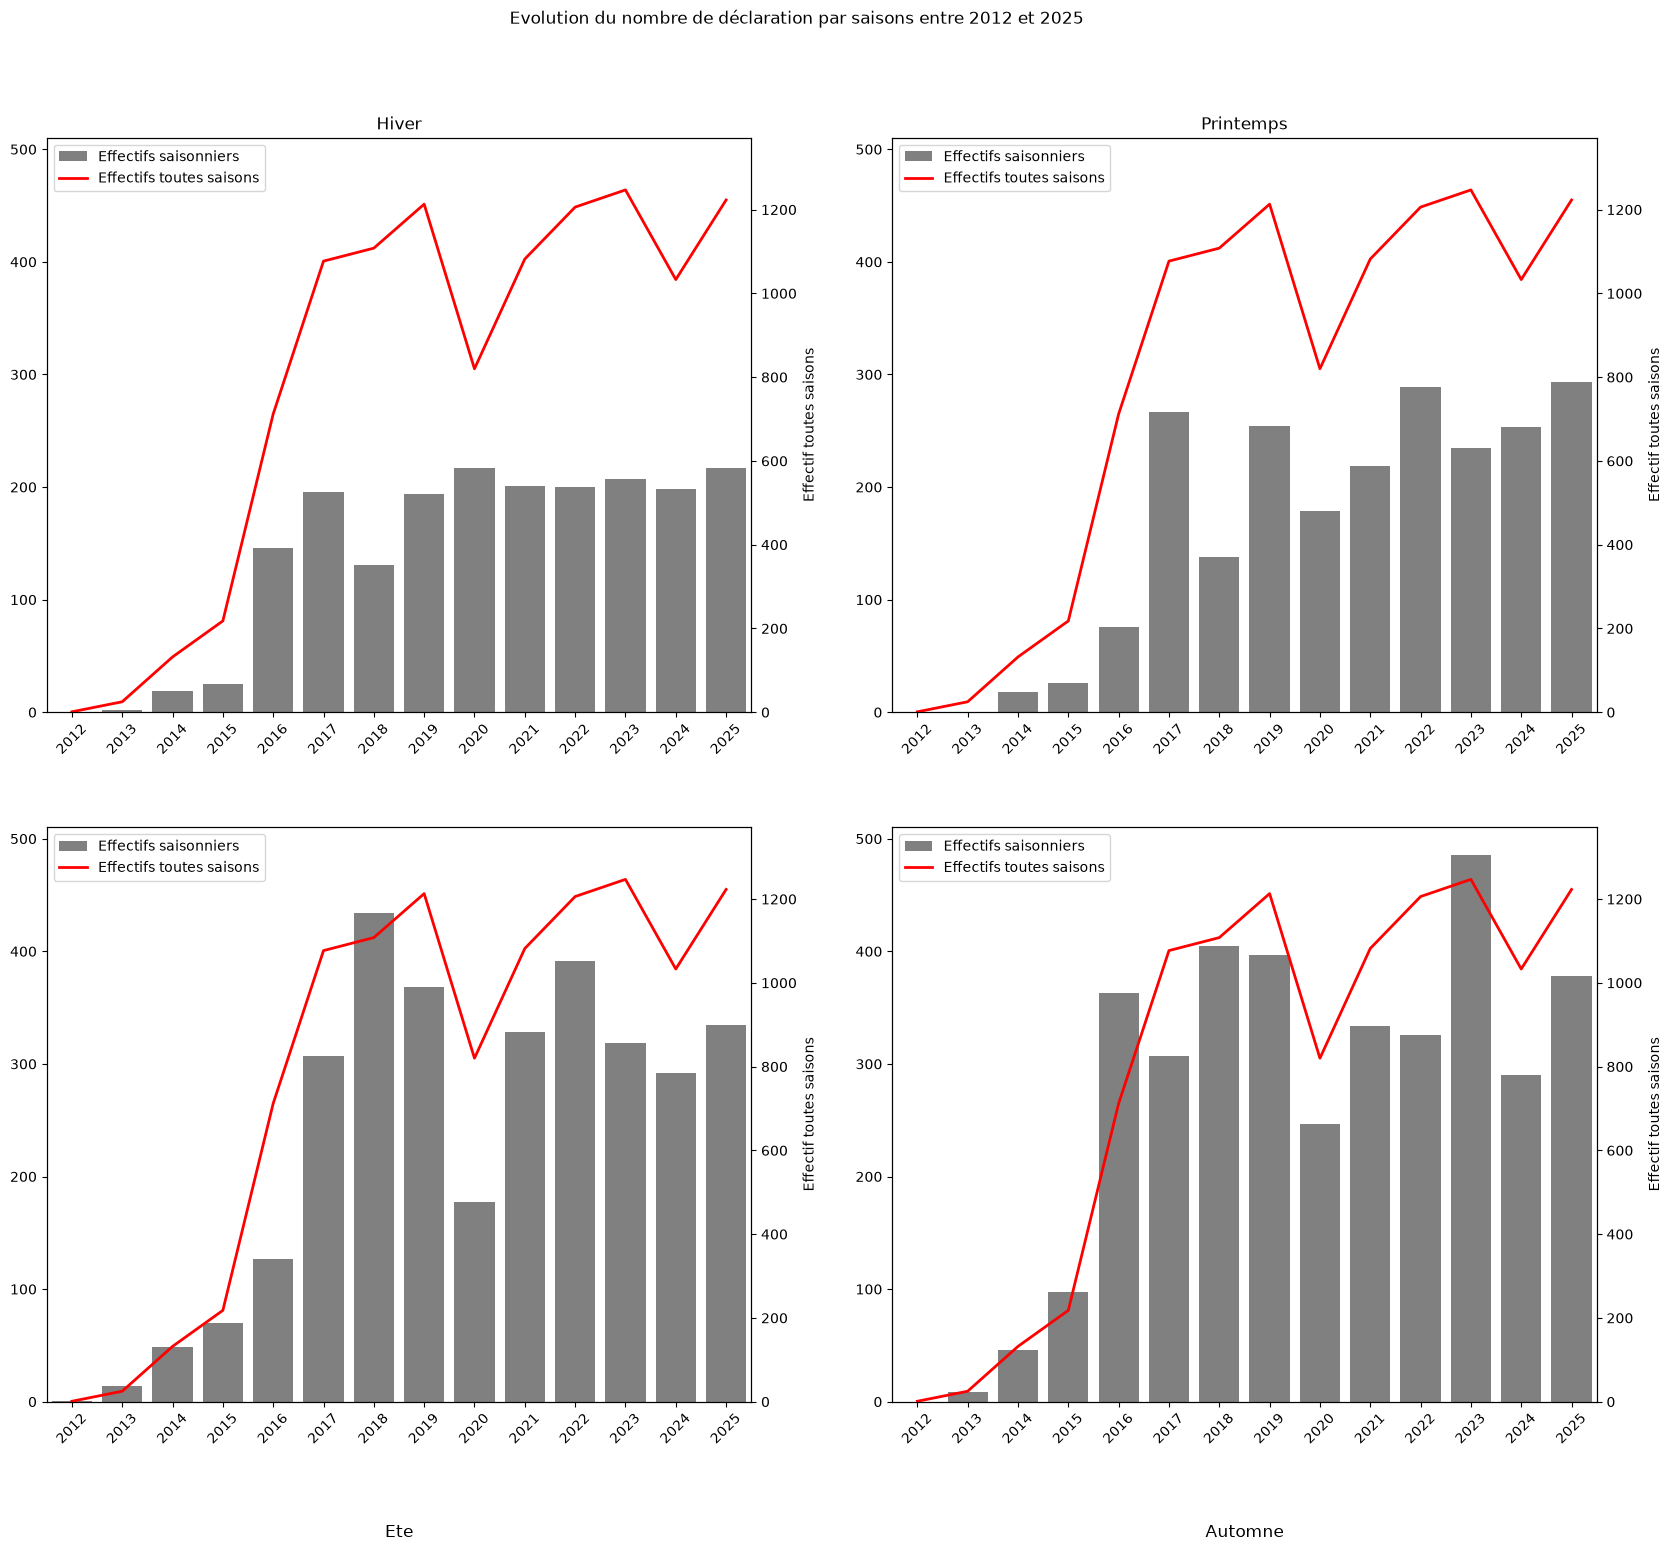

In [19]:
# HISTOGRAMME DE L'EVOLUTION DU NOMBRE DE SIGNALEMENTS SUR LA PERIODE PAR SAISON
# On rajoute la colonne saison au df
conditions = [data['MOISDECL'].isin([12, 1, 2]),
              data['MOISDECL'].isin([3, 4, 5]),
              data['MOISDECL'].isin([6, 7, 8]),
              data['MOISDECL'].isin([9, 10, 11])]
saisons = ["Hiver", "Printemps", "Ete", "Automne"]
data['SAISONDECL'] = np.select(conditions, saisons, default=None)

# pour comparer avec la tendance générale :
annees = sorted(data["ANNEEDECL"].dropna().unique())
tendance_annuelles = (
    data.groupby("ANNEEDECL")
    .size()
    .reindex(annees, fill_value=0)
)

# Les histogrammes
fig, axes1 = plt.subplots(2, 2, figsize=(20, 16))
plt.suptitle("Evolution du nombre de déclaration par saisons entre 2012 et 2025")
plt.subplots_adjust(top=0.90)
ymax_droite = tendance_annuelles.max()*1.1
positions = np.arange(len(tendance_annuelles))
annees = tendance_annuelles.index
for ax, saison in zip(axes1.flat, saisons):
    # 1er axe de gauche : effectifs par saison (les années manquantes à 0)
    effectifs_saison = (
        data.loc[data["SAISONDECL"] == saison, "ANNEEDECL"]
        .value_counts()
        .reindex(tendance_annuelles.index, fill_value=0)
        .sort_index()
    )
    ax.bar(positions, effectifs_saison.values, color='grey',
           label='Effectifs saisonniers')
    ax.set_title(saison)
    ax.set_xlabel("")
    ax.set_xticks(positions)
    ax.set_xticklabels(annees, rotation=45)
    # 2e axe, pour comparer avec la tendance par an
    axe2 = ax.twinx()
    axe2.plot(
        positions,
        tendance_annuelles.values,
        color='red', linestyle='-',
        linewidth=2, label='Effectifs toutes saisons'
    )
    axe2.set_ylim(0, ymax_droite)
    axe2.set_ylabel("Effectif toutes saisons")
    axe2.set_xlim(-0.5, len(tendance_annuelles)-0.5)

    # Légende :
    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = axe2.get_legend_handles_labels()
    ax.legend(h1+h2, l1+l2, loc="upper left")
# même échelle sur l'axe des ordonnées
ymax = max(ax.get_ylim()[1] for ax in axes1.flat)
for ax in axes1.flat:
    ax.set_ylim(0, ymax)
# Améliorer la lisibilité
axes1[1, 0].set_title("Ete", y=-0.25)
axes1[1, 1].set_title("Automne", y=-0.25)

plt.savefig("Outputs/Evolution du nombre de déclarations par saisons entre 2012 et 2025")
plt.show()


Tout d'abord on voit que c'est lors de l'été et de l'automne que les rongeurs sont davantage présents. D'ailleurs, si on voit une certaine régularité (et une petite croissance pour le printemps) dans les nombres de signalements lors des premiers semestres à partir de 2017, c'est que c'est visiblement le deuxième semestre qui est le plus variable, et qui porte majeure partie de la variabilité de la tendance de long terme. L'été et l'automne sont des saisons chaudes plus chaudes en générales, donc cela renforce l'hypothèse ci-dessus, que la chaleur pourrait expliquer en partie la présence de rats. 

# Conclusion
